# 15 - Shift-aware classical models: does reacting to a detected break help SARIMA?

| | |
|---|---|
| **Milestone** | Milestone 2 |
| **Task** | M2-T7 (shift-aware classical models) |
| **Stage** | Stage 3 (forecasting) |
| **Aim** | Compare static SARIMA with two shift-aware versions (restart from the break; a level-shift dummy) and a placebo, using only breaks detected before each origin.<br>Same decision rule and statistics as Milestone 1. |
| **Inputs** | `outputs/m2/tables/m2_sample_items.csv`<br>`outputs/m2/tables/classical_orders.csv`<br>`outputs/m2/tables/classical_metrics_item_origin.csv`<br>`outputs/m2/tables/classical_forecasts.parquet`<br>`data/processed/breaks_by_origin.csv`<br>`data/processed/backtest_errors.csv`<br>`outputs/tables/hc_by_origin.csv` |
| **Outputs** | `outputs/m2/tables/shift_aware_item_origin.csv`<br>`outputs/m2/tables/shift_aware_tests.csv`<br>`outputs/m2/figures/m2_shift_aware.png` |
| **Hypotheses** | H3 (docs/PREREGISTRATION_M2.md) |
| **Expected runtime** | about 3-6 min |

## 1. Setup and config

Shared settings from `src/config.py`.

In [1]:
import os, sys, warnings
sys.path.append("../src")
os.environ["PYTHONPATH"] = os.path.abspath("../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ast import literal_eval
from joblib import Parallel, delayed

from config import (ROOT, INTERIM, PROCESSED, TABLES, M2_TABLES, M2_FIGS, EVAL_ORIGINS, FIT_DAYS, HORIZON, SEED,
                    PRACTICAL_SHARE, FIG_STYLE, make_dirs)
import classical
from metrics import paired_test, holm_adjust

make_dirs()
plt.rcParams.update(FIG_STYLE)
WRITTEN = []

## 2. Load data

Breaks detected at each origin with data up to that origin (Milestone 1, `breaks_by_origin.csv`), the SARIMA orders from notebook 13, and the static SARIMA scores.

In [2]:
sample = pd.read_csv(M2_TABLES / "m2_sample_items.csv")
orders = pd.read_csv(M2_TABLES / "classical_orders.csv").set_index("series")
breaks = pd.read_csv(PROCESSED / "breaks_by_origin.csv",
                     parse_dates=["origin", "last_change_week", "adaptive_start", "placebo_start"])
breaks = breaks[breaks["item_id"].isin(sample["item_id"]) & breaks["origin"].isin(EVAL_ORIGINS)]
scores = pd.read_csv(M2_TABLES / "classical_metrics_item_origin.csv", parse_dates=["origin"])
static = scores[scores["model"] == "sarima"][["item_id", "origin", "mase"]].rename(columns={"mase": "static"})
scales = pd.read_csv(PROCESSED / "backtest_errors.csv", parse_dates=["origin"])[["item_id", "origin", "mase_scale"]].drop_duplicates()
hc = pd.read_csv(TABLES / "hc_by_origin.csv", parse_dates=["origin"])[["item_id", "origin", "high_confidence"]]
long_df = pd.concat([pd.read_csv(INTERIM / f"{c}_candidates.csv", parse_dates=["date"])
                     for c in ["foods", "hobbies", "household"]], ignore_index=True)
daily = {i: g.sort_values("date").reset_index(drop=True) for i, g in long_df.groupby("item_id") if i in set(sample["item_id"])}
print(f"{int(breaks['has_break'].sum())} item-origins with a break, "
      f"{int((~breaks['has_break'] & breaks['placebo_start'].notna()).sum())} placebo item-origins")

449 item-origins with a break, 431 placebo item-origins


## 3. Method

Every variant keeps the item's SARIMA order from notebook 13 and is refitted at each origin.

* **static**: the last 730 days (notebook 13).
* **restart**: only data from the latest detected change week (`adaptive_start`, at least 56 days), and never more than the last 730 days. If the change week is older than the window, restart equals static.
* **dummy**: the last 730 days plus a regressor that is 0 before the change week and 1 after it (and 1 over the horizon). This lets SARIMA shift its level without throwing data away. If the change week is before the window, the dummy would be constant, so the variant equals static.
* **placebo** (control): items with no break get a random start date (the saved Milestone 1 `placebo_start`), capped the same way. If restart helped only because recent data is better, the placebo would help too.

**Decision rule (fixed in advance).** Per item, the mean MASE change vs static over its break origins. A variant *helps* if the Holm-corrected Wilcoxon p (family: restart, dummy) is below 0.05, the median change is below 0, and its size is at least 1% of the median static SARIMA MASE on the same items. Placebo and the high-confidence subset are descriptive.

## 4. Run

Fit the variants for every item-origin that needs one.

In [3]:
def windowed(d, origin, start=None):
    """Data up to the origin, from `start` if given, never more than the last 730 days."""
    n = d["date"].searchsorted(origin, side="right")
    lo = max(0, n - FIT_DAYS)
    if start is not None and not pd.isna(start):
        lo = max(lo, d["date"].searchsorted(start))
    return d.iloc[lo:n]

def item_variants(item, d, rows, order, sorder):
    out = []
    for r in rows.itertuples():
        full = windowed(d, r.origin)
        if r.has_break:
            w = windowed(d, r.origin, r.adaptive_start)
            jobs = [("restart", w, None)]
            dummy = (full["date"] >= r.last_change_week).astype(float).to_numpy()
            jobs.append(("dummy", full, dummy))
        elif not pd.isna(r.placebo_start):
            jobs = [("placebo", windowed(d, r.origin, r.placebo_start), None)]
        else:
            jobs = []
        for variant, w, x in jobs:
            same = (len(w) == len(full)) if x is None else (x.min() == x.max())
            row = {"item_id": item, "origin": r.origin, "variant": variant, "window_days": len(w), "same_as_static": same}
            if not same:
                fc, ok, fb = classical.sarima_forecast(w["sales"].to_numpy(float), order, sorder, HORIZON,
                                                       exog=x, exog_future=None if x is None else np.ones(HORIZON))
                row.update(forecast=list(fc), converged=ok, fallback=fb)
            out.append(row)
    return out

o = orders.copy()
res = Parallel(n_jobs=8)(delayed(item_variants)(i, daily[i], breaks[breaks["item_id"] == i],
                                                literal_eval(o.loc[i, "sarima_order"]), literal_eval(o.loc[i, "sarima_sorder"]))
                         for i in sample["item_id"])
var = pd.DataFrame([r for rows in res for r in rows])
print(var.groupby("variant").agg(item_origins=("item_id", "size"), items=("item_id", "nunique"),
                                 same_as_static=("same_as_static", "mean")).round(3).to_string())

         item_origins  items  same_as_static
variant                                     
dummy             449     75           0.437
placebo           431     76           0.411
restart           449     75           0.437


In [4]:
# Score: variants that equal static get the static score; the others are scored on the 28 test days
act = long_df.set_index(["item_id", "date"])["sales"]
rows = []
for r in var.itertuples():
    if r.same_as_static:
        mase = np.nan
    else:
        days = pd.date_range(r.origin + pd.Timedelta(days=1), periods=HORIZON)
        a = act.loc[[(r.item_id, d) for d in days]].to_numpy()
        sc = scales.loc[(scales["item_id"] == r.item_id) & (scales["origin"] == r.origin), "mase_scale"].iloc[0]
        mase = np.mean(np.abs(a - np.asarray(r.forecast))) / sc
    rows.append({"item_id": r.item_id, "origin": r.origin, "variant": r.variant, "mase_variant": mase,
                 "same_as_static": r.same_as_static, "fallback": getattr(r, "fallback", False) is True,
                 "window_days": r.window_days})
sv = pd.DataFrame(rows).merge(static, on=["item_id", "origin"]).merge(hc, on=["item_id", "origin"], how="left")
sv["mase_variant"] = sv["mase_variant"].fillna(sv["static"])
sv["diff"] = sv["mase_variant"] - sv["static"]
sv["high_confidence"] = sv["high_confidence"].fillna(False).astype(bool)
sv.to_csv(M2_TABLES / "shift_aware_item_origin.csv", index=False)
WRITTEN.append(M2_TABLES / "shift_aware_item_origin.csv")
print(len(sv), "item-origin scores")

1329 item-origin scores


## 5. Results

**H3: the pre-registered test** on all break item-origins, then descriptive views.

In [5]:
def per_item(d):
    return d.groupby("item_id").agg(diff=("diff", "mean"), static=("static", "mean"))

out = []
for group, mask in [("all break item-origins", sv["variant"].isin(["restart", "dummy"])),
                    ("high-confidence breaks", sv["variant"].isin(["restart", "dummy"]) & sv["high_confidence"]),
                    ("only where the variant differs", sv["variant"].isin(["restart", "dummy"]) & ~sv["same_as_static"])]:
    block = []
    for v in ["restart", "dummy"]:
        p = per_item(sv[mask & (sv["variant"] == v)])
        r = {"group": group, "variant": v, **paired_test(p["diff"], seed=SEED), "median_static_mase": p["static"].median()}
        r["practical_threshold"] = PRACTICAL_SHARE * r["median_static_mase"]
        block.append(r)
    for r, ph in zip(block, holm_adjust([b["p_value"] for b in block])):
        r["p_holm"] = ph
        r["helps"] = bool(r["n"] >= 20 and ph < 0.05 and r["median_diff"] < 0 and abs(r["median_diff"]) >= r["practical_threshold"])
    out += block
pl = per_item(sv[sv["variant"] == "placebo"])
out.append({"group": "placebo (no-break item-origins)", "variant": "placebo", **paired_test(pl["diff"], seed=SEED),
            "median_static_mase": pl["static"].median(), "helps": None})
tests = pd.DataFrame(out)
tests.to_csv(M2_TABLES / "shift_aware_tests.csv", index=False)
WRITTEN.append(M2_TABLES / "shift_aware_tests.csv")
cols = ["group", "variant", "n", "median_diff", "ci_low", "ci_high", "share_improved", "p_value", "p_holm", "practical_threshold", "helps"]
print(tests[[c for c in cols if c in tests]].round(4).to_string(index=False))
h3 = not tests[tests["group"] == "all break item-origins"]["helps"].any()
print("\nH3 (no shift-aware variant helps):", "SUPPORTED" if h3 else "NOT SUPPORTED")

                          group variant  n  median_diff  ci_low  ci_high  share_improved  p_value  p_holm  practical_threshold helps
         all break item-origins restart 75       0.0000  0.0000   0.0015          0.1867   0.0013  0.0026               0.0076 False
         all break item-origins   dummy 75       0.0000  0.0000   0.0001          0.2267   0.0287  0.0287               0.0076 False
         high-confidence breaks restart 33       0.0000  0.0000   0.0107          0.2424   0.0301  0.0602               0.0073 False
         high-confidence breaks   dummy 33       0.0000  0.0000   0.0012          0.2121   0.0605  0.0605               0.0073 False
 only where the variant differs restart 47       0.0062  0.0015   0.0107          0.2979   0.0009  0.0017               0.0083 False
 only where the variant differs   dummy 47       0.0010 -0.0003   0.0058          0.3617   0.0210  0.0210               0.0083 False
placebo (no-break item-origins) placebo 76       0.0025  0.0000   0.0

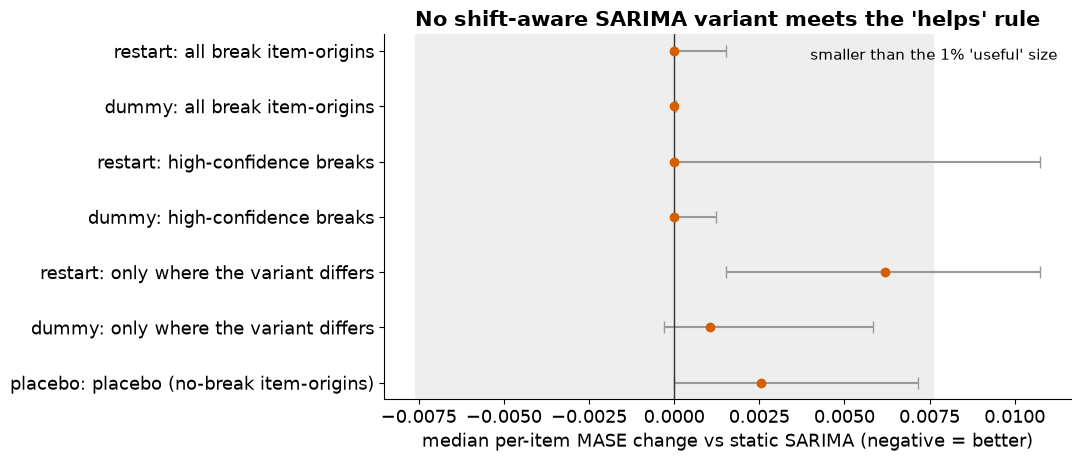

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.8))
t = tests.reset_index(drop=True)
labels = [f"{r.variant}: {r.group}" for r in t.itertuples()]
y = np.arange(len(t))[::-1]
ax.errorbar(t["median_diff"], y, xerr=[t["median_diff"] - t["ci_low"], t["ci_high"] - t["median_diff"]],
            fmt="o", color="#D55E00", ecolor="#999999", capsize=4)
ax.axvline(0, color="#333333", lw=1)
thr = t.loc[0, "practical_threshold"]
ax.axvspan(-thr, thr, color="#EEEEEE", zorder=0, label="smaller than the 1% 'useful' size")
ax.set_yticks(y, labels)
ax.set_xlabel("median per-item MASE change vs static SARIMA (negative = better)")
ax.set_title("No shift-aware SARIMA variant meets the 'helps' rule" if h3 else "A shift-aware SARIMA variant meets the 'helps' rule")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(M2_FIGS / "m2_shift_aware.png")
WRITTEN.append(M2_FIGS / "m2_shift_aware.png")
plt.show()

## 6. Checks

In [7]:
# every break item-origin got both variants; placebo only on no-break item-origins
b = breaks[breaks["has_break"]]
assert len(sv[sv["variant"] == "restart"]) == len(b) == len(sv[sv["variant"] == "dummy"])
assert sv[sv["variant"] == "placebo"].merge(b, on=["item_id", "origin"]).empty
# only breaks known at the origin were used: the change week is always before the origin
assert (b["last_change_week"] < b["origin"]).all()
print("fallbacks:", int(sv["fallback"].sum()), "of", int((~sv["same_as_static"]).sum()), "fitted variants")
print("all checks passed")

fallbacks: 0 of 760 fitted variants
all checks passed


## 7. Interpretation

**We expected (H3)** no shift-aware variant to help, as for LightGBM in Milestone 1.
**We found** exactly that: **H3 supported**.
* On all 449 break item-origins (75 items): restart and dummy both have a median per-item change of 0.0000, because **44%** of break item-origins have a break older than the 730-day window, where the variant is the static model.
* Where the variant actually differs (47 items): **restart is worse**, +0.0062 MASE (95% CI +0.0015 to +0.0107, Holm p = 0.002), better for only 30% of items; the **level-shift dummy** is +0.0010 (−0.0003 to +0.0058), not better.
* The **placebo** (a random cut on items without a break) is also slightly worse (+0.0025), so using less data does not help either.
* High-confidence breaks (33 items) give the same picture.

The classical family agrees with Milestone 1: detected breaks are too late and too coarse to improve a model that already re-estimates its level at every origin.

## 8. What comes next

* Notebook **16** puts SARIMA and Holt-Winters forecasts into the stock simulation.

In [8]:
# Files written by this notebook
for p in WRITTEN:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\m2\tables\shift_aware_item_origin.csv 141 KB
outputs\m2\tables\shift_aware_tests.csv 2 KB
outputs\m2\figures\m2_shift_aware.png 83 KB
